# 01 - Preprocessing

### `Objective` - Predict customer next month spend (`spend_next_month`)

This notebook loads the raw data, checks it and cleans it. Output: `data/processed/cleaned.csv`

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

sns.set(style="darkgrid")

In [2]:
df = pd.read_csv('data/raw/customer_spend_dataset.csv')

Initial Dataset View

In [3]:
df.head()

,customer_id,snapshot_date,age,gender,region,education,household_size,has_children,annual_income,tenure_months,...,email_open_rate,email_click_rate,push_enabled,cart_abandon_rate,wishlist_items,support_tickets_90d,campaign_responses_6m,target_month,promo_planned_next_month,spend_next_month
0,C100000,2024-10-31,42,F,Suburban,High school,2,0,29400.0,40,...,0.205,0.032,0,0.651,4,0,0,11,0,106.67
1,C100001,2023-10-31,26,F,Urban,Master,2,0,46200.0,72,...,0.499,0.086,1,0.497,1,0,1,11,1,296.00
2,C100002,2024-02-29,47,M,Urban,Bachelor,5,0,42500.0,33,...,0.280,0.096,1,0.638,2,0,0,3,1,121.78
3,C100003,2023-08-31,49,M,Suburban,Master,3,1,64500.0,35,...,0.464,0.096,1,0.359,3,0,2,9,1,367.96
4,C100004,2024-11-30,18,M,Suburban,Bachelor,4,1,44000.0,48,...,0.573,0.241,1,0.693,2,0,1,12,0,165.40


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 40 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               25000 non-null  object 
 1   snapshot_date             25000 non-null  object 
 2   age                       25000 non-null  int64  
 3   gender                    25000 non-null  object 
 4   region                    25000 non-null  object 
 5   education                 24034 non-null  object 
 6   household_size            25000 non-null  int64  
 7   has_children              25000 non-null  int64  
 8   annual_income             23441 non-null  float64
 9   tenure_months             25000 non-null  int64  
 10  membership_tier           25000 non-null  object 
 11  preferred_channel         25000 non-null  object 
 12  loyalty_points            25000 non-null  int64  
 13  spend_last_1m             25000 non-null  float64
 14  spend_

In [5]:
df.shape

(25000, 40)

In [6]:
df.nunique().to_frame(name='Count of unique values')

,Count of unique values
customer_id,25000
snapshot_date,18
age,63
gender,3
region,3
education,4
household_size,6
has_children,2
annual_income,1066
tenure_months,120


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,25000.0,38.335040,11.535897,18.000,30.0000,38.000,46.0000,80.000
household_size,25000.0,2.593720,1.237707,1.000,2.0000,2.000,3.0000,6.000
has_children,25000.0,0.359440,0.479846,0.000,0.0000,0.000,1.0000,1.000
annual_income,23441.0,45701.160360,18358.107555,12000.000,32700.0000,42500.000,55200.0000,198200.000
tenure_months,25000.0,30.849240,20.558056,1.000,16.0000,26.000,41.0000,120.000
loyalty_points,25000.0,2445.007040,2796.207512,73.000,897.0000,1545.500,2860.0000,46342.000
spend_last_1m,25000.0,331.601051,361.907252,0.000,111.2275,223.725,421.1025,5972.670
spend_prev_2m,25000.0,326.742825,349.132795,0.000,113.9125,222.985,414.0475,5382.310
avg_spend_3m,25000.0,327.666729,332.349586,0.000,125.4150,227.030,409.2925,4844.780
avg_spend_6m,25000.0,326.412074,322.324411,3.730,129.7875,229.735,407.2850,4698.300


In [8]:
df.describe(include='O')

,customer_id,snapshot_date,gender,region,education,membership_tier,preferred_channel
count,25000,25000,25000,25000,24034,25000,25000
unique,25000,18,3,3,4,3,3
top,C100000,2023-08-31,F,Urban,Bachelor,Basic,App
freq,1,1439,12378,11973,10813,12612,9420


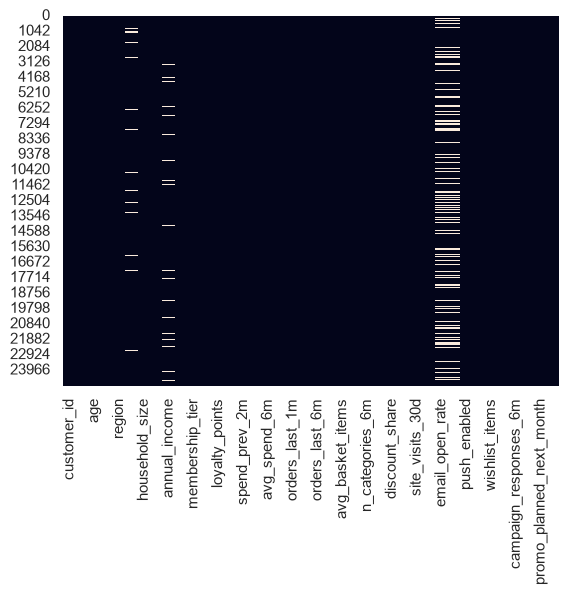

In [9]:
sns.heatmap(df.isnull(), cbar=False)
plt.show()

In [10]:
df.isnull().sum()

customer_id                    0
snapshot_date                  0
age                            0
gender                         0
region                         0
education                    966
household_size                 0
has_children                   0
annual_income               1559
tenure_months                  0
membership_tier                0
preferred_channel              0
loyalty_points                 0
spend_last_1m                  0
spend_prev_2m                  0
avg_spend_3m                   0
avg_spend_6m                   0
spend_trend_ratio              6
orders_last_1m                 0
orders_last_3m                 0
orders_last_6m                 0
avg_order_value_6m             0
avg_basket_items               0
days_since_last_purchase       0
n_categories_6m                0
return_rate                    0
discount_share                 0
app_sessions_30d               0
site_visits_30d                0
email_subscribed               0
email_open